# Lecture 5 companion: a robot project, CPM, crashing, and PERT

**15–20 minute instructor demonstration.** Six synthetic tasks make the calculations small enough to check by hand. This prepares you for [Lab 5's full inspection-robot project](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_5.ipynb), including supplier choices, crashing, risk mitigation, and Monte Carlo.

1. Forward/backward passes, connected critical paths, and a Gantt chart (5 min).
2. Buy the cheapest project improvement rather than the cheapest task improvement (4 min).
3. Compare PERT with explicit distributional simulation (6 min).

Run all cells in order. Required: `numpy scipy pandas matplotlib`; optional: `ipywidgets`. If necessary install them with `%pip install numpy scipy pandas matplotlib ipywidgets`. No network access or additional graph/optimization packages are needed. Every control has a direct callable fallback. Days mean consistent working days; all costs are incremental teaching values in PLN.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, beta
from IPython.display import display
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False})
TASKS = pd.DataFrame([
    ('A','Freeze design',(),2),
    ('B','Procure hardware',('A',),3),
    ('C','Build perception demo',('A',),4),
    ('D','Assemble robot',('B',),2),
    ('E','Integrate system',('C','D'),3),
    ('F','Validate demonstration',('E',),2)
],columns=['id','name','predecessors','duration']).set_index('id')
display(TASKS)

,name,predecessors,duration
id,,,
A,Freeze design,(),2
B,Procure hardware,"(A,)",3
C,Build perception demo,"(A,)",4
D,Assemble robot,"(B,)",2
E,Integrate system,"(C, D)",3
F,Validate demonstration,"(E,)",2


## 1. The two-pass calculation

The network is activity-on-node: an arrow means the predecessor must finish before the successor starts. No resource capacities are included yet.

$$ES_i=\max_{p\in pred(i)}EF_p,\quad EF_i=ES_i+d_i,$$
$$LF_i=\min_{s\in succ(i)}LS_s,\quad LS_i=LF_i-d_i,\quad slack_i=LS_i-ES_i.$$

Use zero for the earliest start of an initial task; set each terminal latest finish to the earliest possible project finish. The implementation below derives an order from the dependencies, checks missing IDs and cycles, and does not rely on row order.

,duration,ES,EF,LS,LF,slack
id,,,,,,
A,2,0.0,2.0,0.0,2.0,0.0
B,3,2.0,5.0,2.0,5.0,0.0
C,4,2.0,6.0,3.0,7.0,1.0
D,2,5.0,7.0,5.0,7.0,0.0
E,3,7.0,10.0,7.0,10.0,0.0
F,2,10.0,12.0,10.0,12.0,0.0


Finish day: 12.0 ; critical paths: ['A → B → D → E → F']


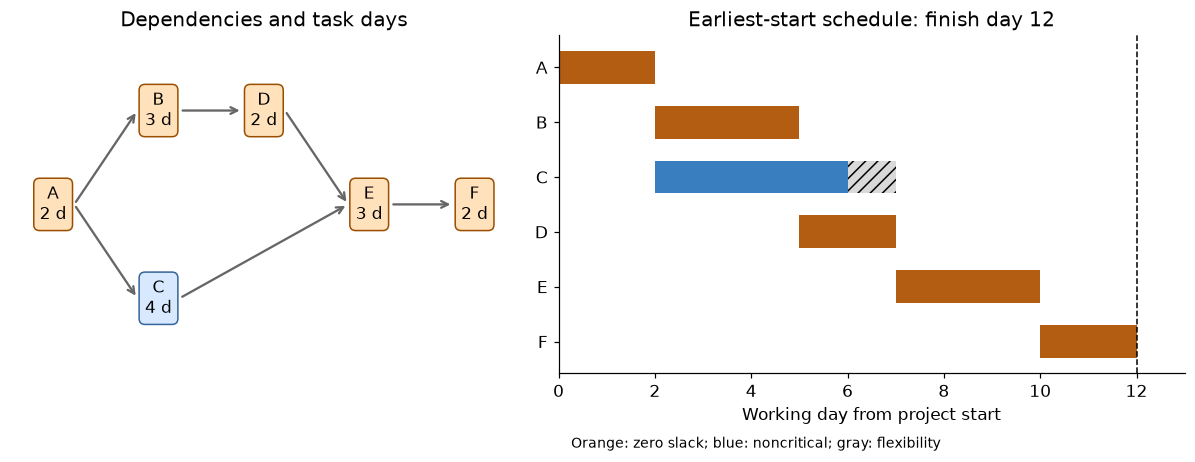

In [2]:
def topology(tasks):
    if not tasks.index.is_unique:
        raise ValueError('Task IDs must be unique.')
    ids = list(tasks.index)
    successors = {i:[] for i in ids}
    for i in ids:
        for p in tasks.loc[i,'predecessors']:
            if p not in successors:
                raise ValueError(f'Unknown predecessor {p} of {i}')
            successors[p].append(i)
    remaining = {i:len(tasks.loc[i,'predecessors']) for i in ids}
    ready = [i for i in ids if remaining[i] == 0]
    order = []
    while ready:
        i = ready.pop(0); order.append(i)
        for j in successors[i]:
            remaining[j] -= 1
            if remaining[j] == 0: ready.append(j)
    if len(order) != len(ids):
        raise ValueError('Dependencies contain a directed cycle.')
    return order, successors

def compute_cpm(tasks):
    order, successors = topology(tasks)
    duration = tasks.duration.astype(float).to_dict()
    if not all(np.isfinite(d) and d >= 0 for d in duration.values()):
        raise ValueError('Durations must be finite and nonnegative.')
    es, ef, ls, lf = {}, {}, {}, {}
    for i in order:
        es[i] = max((ef[p] for p in tasks.loc[i,'predecessors']), default=0.0)
        ef[i] = es[i] + duration[i]
    finish = max(ef.values(),default=0.0)
    for i in reversed(order):
        lf[i] = min((ls[j] for j in successors[i]), default=finish)
        ls[i] = lf[i] - duration[i]
    result = tasks.copy()
    for name,values in [('ES',es),('EF',ef),('LS',ls),('LF',lf)]:
        result[name] = pd.Series(values)
    result['slack'] = result.LS - result.ES
    result['critical'] = np.isclose(result.slack,0)
    return result, finish

def complete_paths(tasks):
    _, successors = topology(tasks)
    def walk(i):
        if not successors[i]: return [(i,)]
        return [(i,)+p for j in successors[i] for p in walk(j)]
    return [p for i in tasks.index if not tasks.loc[i,'predecessors'] for p in walk(i)]

def critical_paths(tasks, cpm_table):
    paths = complete_paths(tasks)
    return [path for path in paths if all(cpm_table.loc[i,'critical'] for i in path)
            and all(np.isclose(cpm_table.loc[a,'EF'],cpm_table.loc[b,'ES'])
                    for a,b in zip(path[:-1],path[1:]))]

def altered_tasks(b_reduction=0):
    tasks = TASKS.copy()
    tasks.loc['B','duration'] -= b_reduction
    return tasks

def plot_project(table, finish):
    fig, axes = plt.subplots(1,2,figsize=(11,4.4),gridspec_kw={'width_ratios':[1.05,1.3]})
    positions = {'A':(0,.5),'B':(1,1),'C':(1,0),'D':(2,1),'E':(3,.5),'F':(4,.5)}
    ax = axes[0]
    for i,row in table.iterrows():
        x,y = positions[i]
        for p in row.predecessors:
            xp,yp = positions[p]
            ax.annotate('',xy=(x-.20,y),xytext=(xp+.20,yp),
                        arrowprops={'arrowstyle':'->','color':'0.4','lw':1.5})
        ax.text(x,y,f'{i}\n{row.duration:g} d',ha='center',va='center',
                bbox={'boxstyle':'round,pad=.35','facecolor':'#ffe2bb' if row.critical else '#d8e9ff',
                      'edgecolor':'#9b4e00' if row.critical else '#356599'})
    ax.set(xlim=(-.4,4.4),ylim=(-.4,1.4),title='Dependencies and task days'); ax.axis('off')
    ax = axes[1]
    for k,(i,row) in enumerate(table.iterrows()):
        ax.barh(k,row.duration,left=row.ES,color='#b35d12' if row.critical else '#397fc0',height=.6)
        if row.slack > 1e-8:
            ax.barh(k,row.slack,left=row.EF,color='0.85',hatch='///',height=.6)
    ax.set(yticks=np.arange(len(table)),yticklabels=table.index,xlabel='Working day from project start',
           title=f'Earliest-start schedule: finish day {finish:g}',xlim=(0,max(13,finish+1)))
    ax.invert_yaxis(); ax.axvline(finish,ls='--',color='black',lw=1)
    ax.text(.02,-.22,'Orange: zero slack; blue: noncritical; gray: flexibility',
            transform=ax.transAxes,fontsize=9)
    fig.tight_layout()
    return fig

def project_demo(b_reduction=0, show=True):
    tasks = altered_tasks(b_reduction)
    table, finish = compute_cpm(tasks)
    paths = critical_paths(tasks,table)
    fig = plot_project(table,finish)
    if show:
        display(table[['duration','ES','EF','LS','LF','slack']])
        print('Finish day:',finish,'; critical paths:', [' → '.join(p) for p in paths])
        plt.show()
    return {'tasks':tasks,'table':table,'finish':finish,'critical_paths':paths,'figure':fig}

baseline_project = project_demo()

**Hand check:** A–B–D–E–F lasts $2+3+2+3+2=12$ days. A–C–E–F lasts $2+4+3+2=11$. C has one day of slack, $LS-ES=3-2$.

**Predict:** if B gets one day shorter, does the project also get one day shorter? How many critical paths will there be? A list of all zero-slack tasks is not necessarily one connected path.

interactive(children=(IntSlider(value=0, continuous_update=False, description='B days saved', max=1), Output()…

,duration,ES,EF,LS,LF,slack
id,,,,,,
A,2,0.0,2.0,0.0,2.0,0.0
B,2,2.0,4.0,2.0,4.0,0.0
C,4,2.0,6.0,2.0,6.0,0.0
D,2,4.0,6.0,4.0,6.0,0.0
E,3,6.0,9.0,6.0,9.0,0.0
F,2,9.0,11.0,9.0,11.0,0.0


Finish day: 11.0 ; critical paths: ['A → B → D → E → F', 'A → C → E → F']


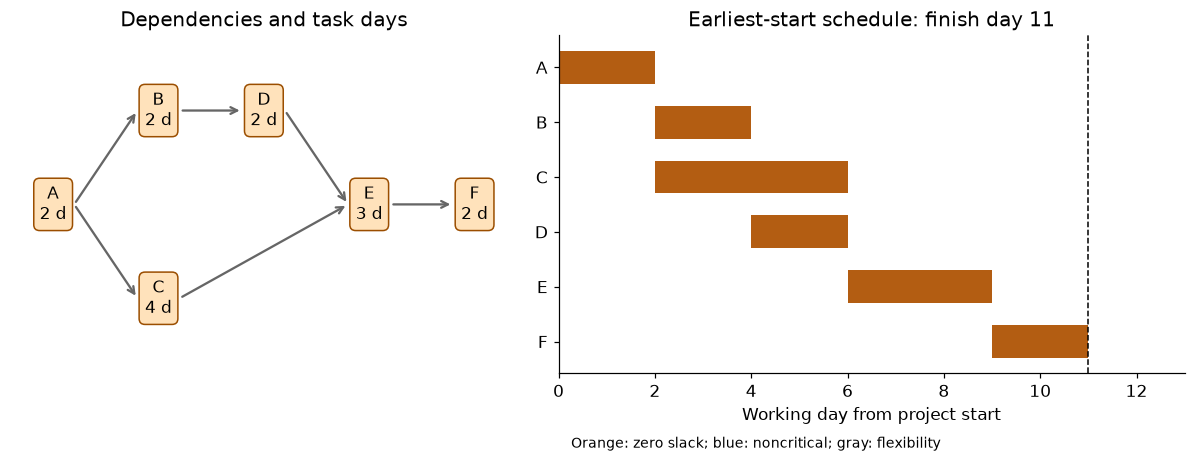

In [3]:
# Optional control; direct fallback: project_demo(b_reduction=1)
try:
    import ipywidgets as widgets
except ImportError:
    print('Call project_demo(1) directly.')
else:
    display(widgets.interactive(project_demo,
        b_reduction=widgets.IntSlider(value=0,min=0,max=1,description='B days saved',
                                      continuous_update=False),show=widgets.fixed(True)))
multiple_paths = project_demo(1)

**Answer:** finish becomes day 11, with **two** critical paths. Shortening just C after that saves no project time, because A–B–D–E–F still takes 11. Shortening just D also saves no time, because A–C–E–F takes 11.

## 2. Crashing: compare complete feasible plans

Each of B, C, D, E, F can be shortened by one day, at most once. Costs are 100, 40, 150, 200, 300 PLN respectively. Find the least expensive combination that finishes by day 10. The 32 combinations are small enough to enumerate exactly.

In [4]:
CRASH_COST = {'B':100,'C':40,'D':150,'E':200,'F':300}

def enumerate_crash_plans(deadline=10):
    rows=[]
    for choices in itertools.product([0,1],repeat=len(CRASH_COST)):
        reductions = dict(zip(CRASH_COST,choices))
        tasks = TASKS.copy()
        for i,r in reductions.items(): tasks.loc[i,'duration'] -= r
        _, finish = compute_cpm(tasks)
        rows.append({'plan':','.join(i for i,r in reductions.items() if r) or 'none',
                     'cost_PLN':sum(CRASH_COST[i]*r for i,r in reductions.items()),
                     'finish_day':finish,'meets_deadline':finish<=deadline,
                     **{f'reduce_{i}':r for i,r in reductions.items()}})
    return pd.DataFrame(rows).sort_values(['cost_PLN','finish_day']).reset_index(drop=True)

all_plans = enumerate_crash_plans()
feasible_plans = all_plans[all_plans.meets_deadline]
display(feasible_plans.head(6))

,plan,cost_PLN,finish_day,meets_deadline,reduce_B,reduce_C,reduce_D,reduce_E,reduce_F
9,"B,C,D",290,10.0,True,1,1,1,0,0
10,"B,E",300,10.0,True,1,0,0,1,0
12,"B,C,E",340,10.0,True,1,1,0,1,0
14,"D,E",350,10.0,True,0,0,1,1,0
15,"C,D,E",390,10.0,True,0,1,1,1,0
16,"B,F",400,10.0,True,1,0,0,0,1


**Answer:** buy B, C, and D reductions for $100+40+150=290$ PLN. Both full paths become 10 days. Buying B and shared E also reaches 10 but costs 300 PLN. Cheap C alone saves zero project days in the baseline.

**Resource check:** the CPM result assumes tasks can overlap whenever their predecessors allow it. If B and C need the same engineer, B then C gives a 14-day finish; C then B gives 16. The 12-day CPM baseline is a precedence-only lower bound, not a promise that resources exist. See the scheduling laboratory for explicit resource constraints.

## 3. PERT and explicit distribution assumptions

For task duration $d$, use symmetric three-point estimates $(a,m,b)=(d-h,d,d+h)$, with uncertainty half-width $h$. Traditional PERT assigns mean $d$ and approximate variance $h^2/9$. Summing along one expected critical path and applying a normal approximation ignores path switching.

For Monte Carlo we follow the lab's scaled beta family with weight four:

$$\alpha=1+4(m-a)/(b-a),\quad\beta=1+4(b-m)/(b-a).$$

In this symmetric example $\alpha=\beta=3$. Its mean is still $d$ but its **exact variance is $h^2/7$, not $h^2/9$**. We show a second fixed-path normal calculation using those exact beta variances. Comparing that result with a simulation of the same fixed path helps isolate the normal approximation; comparing simulated fixed-path and full-network finishes isolates path switching.

Shared tasks receive one draw per simulation. We do not draw A twice just because it lies on two paths. Task durations are independent here; shared suppliers or people can invalidate that assumption.

30,000 trials, seed 505; fixed reference path: A → B → D → E → F
Per-task variance: textbook = 0.1111 ; actual beta = 0.1429 days²


,value
CPM on task means (days),12.0000
Traditional PERT normal deadline probability,0.9101
Normal using exact beta variance,0.8816
Simulated fixed-path deadline probability,0.8818
Simulated full-network deadline probability,0.8813
Monte Carlo standard error (probability),0.0019
Simulated mean project finish (days),12.0106
Simulated 90th-percentile finish (days),13.0820


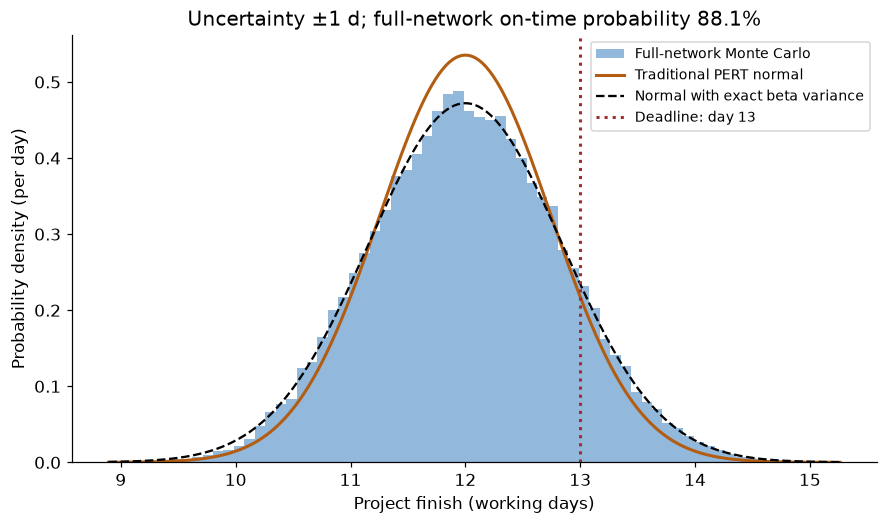

In [5]:
def risk_demo(half_width=1.0, deadline=13.0, b_reduction=0, trials=30000, show=True):
    tasks = altered_tasks(b_reduction)
    means = tasks.duration.to_numpy(dtype=float)
    if half_width <= 0 or half_width >= means.min():
        raise ValueError('Half-width must be positive and smaller than each task mean.')
    table, mean_cpm_finish = compute_cpm(tasks)
    # Choose one expected critical path for the textbook approximation.
    path = critical_paths(tasks,table)[0]
    ids = list(tasks.index)
    indices = [ids.index(i) for i in path]
    n_path = len(path)
    textbook_sd = np.sqrt(n_path*half_width**2/9)
    beta_variance = float(beta.var(3,3,loc=-half_width,scale=2*half_width))
    exact_beta_sd = np.sqrt(n_path*beta_variance)
    rng = np.random.default_rng(505)
    samples = means + half_width*(2*rng.beta(3,3,size=(trials,len(tasks)))-1)
    order, _ = topology(tasks)
    ef = {}
    for i in order:
        es = np.maximum.reduce([ef[p] for p in tasks.loc[i,'predecessors']]) if tasks.loc[i,'predecessors'] else np.zeros(trials)
        ef[i] = es + samples[:,ids.index(i)]
    project_finishes = np.maximum.reduce(list(ef.values()))
    fixed_path_finishes = samples[:,indices].sum(axis=1)
    p_project = float(np.mean(project_finishes <= deadline))
    mc_se = np.sqrt(p_project*(1-p_project)/trials)
    summary = pd.Series({
        'CPM on task means (days)':mean_cpm_finish,
        'Traditional PERT normal deadline probability':norm.cdf((deadline-mean_cpm_finish)/textbook_sd),
        'Normal using exact beta variance':norm.cdf((deadline-mean_cpm_finish)/exact_beta_sd),
        'Simulated fixed-path deadline probability':np.mean(fixed_path_finishes<=deadline),
        'Simulated full-network deadline probability':p_project,
        'Monte Carlo standard error (probability)':mc_se,
        'Simulated mean project finish (days)':project_finishes.mean(),
        'Simulated 90th-percentile finish (days)':np.quantile(project_finishes,.9)})
    fig, ax = plt.subplots(figsize=(8.2,4.9))
    ax.hist(project_finishes,bins=70,density=True,color='#397fc0',alpha=.55,
            label='Full-network Monte Carlo')
    xx = np.linspace(project_finishes.min(),project_finishes.max(),400)
    ax.plot(xx,norm.pdf(xx,mean_cpm_finish,textbook_sd),color='#b35d12',lw=2,
            label='Traditional PERT normal')
    ax.plot(xx,norm.pdf(xx,mean_cpm_finish,exact_beta_sd),'--',color='black',lw=1.5,
            label='Normal with exact beta variance')
    ax.axvline(deadline,color='#a22c30',ls=':',lw=2,label=f'Deadline: day {deadline:g}')
    ax.set(xlabel='Project finish (working days)',ylabel='Probability density (per day)',
           title=f'Uncertainty ±{half_width:g} d; full-network on-time probability {p_project:.1%}')
    ax.legend(fontsize=9); fig.tight_layout()
    if show:
        print(f'{trials:,} trials, seed 505; fixed reference path:', ' → '.join(path))
        print('Per-task variance: textbook =',round(half_width**2/9,4),
              '; actual beta =',round(beta_variance,4),'days²')
        display(summary.to_frame('value').round(4)); plt.show()
    return {'summary':summary,'project_finishes':project_finishes,
            'fixed_path_finishes':fixed_path_finishes,'figure':fig,
            'beta_variance':beta_variance,'reference_path':path}

baseline_risk = risk_demo()

In [6]:
# Optional controls. Direct fallback: risk_demo(half_width=1.8,deadline=12,b_reduction=1)
try:
    import ipywidgets as widgets
except ImportError:
    print('Call risk_demo(...) directly.')
else:
    display(widgets.interactive(risk_demo,
        half_width=widgets.FloatSlider(value=1,min=.2,max=1.8,step=.2,
                                       description='Half-width',continuous_update=False),
        deadline=widgets.FloatSlider(value=13,min=10,max=15,step=.5,
                                      description='Deadline',continuous_update=False),
        b_reduction=widgets.IntSlider(value=0,min=0,max=1,
                                     description='B days saved',continuous_update=False),
        trials=widgets.fixed(30000),show=widgets.fixed(True)))

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Half-width', max=1.8, min=0…

**Try:** set B's reduction to 1, half-width to 0.8, and deadline to 11. Both expected paths now take 11 days. A single symmetric fixed path finishes by its own mean about half the time. The whole project must satisfy **both** paths, so its on-time probability is smaller. The full-network finish is the maximum, not the average, of the two path finishes.

The control shortens B from three days to two. All supplied half-widths stay below every task mean, so sampled durations stay positive. Do not extrapolate a symmetric duration model to negative durations.

**Think further:** adding a task for interface review may reduce the variance and mean of later integration. Model the revised network and distributions together rather than concluding that more tasks always mean more deadline risk. The laboratory develops this larger decision.

In [7]:
# Numerical checks of the worked lecture example and stochastic model.
t = baseline_project['table']
assert baseline_project['finish'] == 12
assert t.loc['C','slack'] == 1 and t.loc['C','LS'] == 3
assert baseline_project['critical_paths'] == [('A','B','D','E','F')]
assert multiple_paths['finish'] == 11 and len(multiple_paths['critical_paths']) == 2
assert len(all_plans) == 32
assert feasible_plans.iloc[0]['cost_PLN'] == 290
assert feasible_plans.iloc[0]['plan'] == 'B,C,D'
assert np.isclose(norm.cdf(1/np.sqrt(5/9)),.91014375,atol=1e-6)
assert np.isclose(baseline_risk['beta_variance'],1/7)
# Every sampled project is at least as long as the fixed reference path.
assert np.all(baseline_risk['project_finishes'] >= baseline_risk['fixed_path_finishes']-1e-10)
# Large seeded sample reproduces the specified fixed-path moments within sampling error.
assert abs(baseline_risk['fixed_path_finishes'].mean()-12) < .03
assert abs(baseline_risk['fixed_path_finishes'].var()-5/7) < .04
# Graph validation is exercised, rather than trusting accidental row order.
shuffled, shuffled_finish = compute_cpm(TASKS.iloc[::-1])
assert shuffled_finish == 12 and shuffled.loc['C','slack'] == 1
cyclic = TASKS.copy(); cyclic.at['A','predecessors'] = ('F',)
try:
    compute_cpm(cyclic)
except ValueError as exc:
    assert 'cycle' in str(exc)
else:
    raise AssertionError('Cycle was not detected.')
print('All CPM, crashing, graph validation, and stochastic-moment checks passed.')

All CPM, crashing, graph validation, and stochastic-moment checks passed.


## What to report in the laboratory

- **Baseline:** finish day, a connected critical path, slack in days, and the resource assumptions.
- **Decision:** incremental PLN, project days saved, revised critical paths, and the chosen deadline.
- **Risk:** three-point estimates, exact sampling distribution, any correlations, simulation size and seed, on-time probability, and its Monte Carlo standard error.

Simulation uncertainty is not the same as uncertainty about whether your input estimates are credible. A larger trial count reduces Monte Carlo noise but does not correct an unrealistic supplier estimate or missing dependency.

Sources: [NASA Schedule Management Overview](https://www.nasa.gov/ocfo/ppc-corner/schedule-management-overview/), [NASA PP&C glossary](https://www.nasa.gov/ocfo/ppc-corner/ppc-glossary/), [SciPy beta distribution and moments](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html), and [upstream Lab 5](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_5.ipynb), reviewed at commit `3c1b7a70f5990d7665b11a7a853eaf1061a36d30`.